# AirWatch India: Exploring Air Pollution Through Data Visualization

## Project Overview

Air pollution is an important environmental and public-health concern in India. Understanding how pollutant concentrations vary across locations and over time can help identify patterns that deserve further investigation.

This project uses the India Air Quality dataset from Kaggle to explore historical air pollution records, compare locations, investigate seasonal patterns, and evaluate changes over time.

### Project Objectives
1. Understand the structure and quality of the dataset.
2. Explore historical trends in recorded pollutant concentrations.
3. Compare pollution levels across Indian locations and states.
4. Investigate monthly and seasonal variation.
5. Examine relationships between available pollutants.
6. Develop evidence-based hypotheses and, if the data supports it, a baseline predictive model.

### Research Question

**How do recorded air pollutant concentrations vary across Indian locations and over time, and what temporal, regional, and seasonal patterns can be identified?**

### Dataset

Source: [India Air Quality Dataset — Kaggle](https://www.kaggle.com/datasets/shrutibhargava94/india-air-quality-data/data)

### Important Note

Pollutant concentration and the Air Quality Index (AQI) are not the same. This project analyzes the pollutant measurements available in the dataset and will not label them as AQI unless a valid AQI field or appropriate calculation is available.


## 1. Import Libraries

We use Pandas and NumPy for data processing, Matplotlib and Seaborn for visualization, and scikit-learn later if a predictive model is appropriate.

The notebook will use consistent formatting so that the visualizations are suitable for analysis and presentation.


In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"
DATA_PATH = "data.csv"

df = pd.read_csv(
    DATA_PATH,
    encoding="cp1252",
    low_memory=False
)

print("Dataset loaded successfully!")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

display(df.head())

Dataset loaded successfully!
Rows: 435,742
Columns: 13


,stn_code,sampling_date,state,location,agency,type,so2,no2,rspm,spm,location_monitoring_station,pm2_5,date
0,150,February - M021990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",4.8,17.4,NaN,NaN,NaN,NaN,1990-02-01
1,151,February - M021990,Andhra Pradesh,Hyderabad,NaN,Industrial Area,3.1,7.0,NaN,NaN,NaN,NaN,1990-02-01
2,152,February - M021990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",6.2,28.5,NaN,NaN,NaN,NaN,1990-02-01
3,150,March - M031990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",6.3,14.7,NaN,NaN,NaN,NaN,1990-03-01
4,151,March - M031990,Andhra Pradesh,Hyderabad,NaN,Industrial Area,4.7,7.5,NaN,NaN,NaN,NaN,1990-03-01


## 2. Understand the Dataset

Before creating visualizations, we need to understand what the dataset contains.

We will inspect the column names, data types, sample records, and date coverage. This helps us choose suitable variables and avoid drawing conclusions from fields that are incorrectly formatted or unavailable.

In [2]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nSummary statistics for numeric columns:")
display(df.describe(include="all").T)

print("\nFirst five records:")
display(df.head())

Column names:
['stn_code', 'sampling_date', 'state', 'location', 'agency', 'type', 'so2', 'no2', 'rspm', 'spm', 'location_monitoring_station', 'pm2_5', 'date']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 435742 entries, 0 to 435741
Data columns (total 13 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   stn_code                     291665 non-null  object 
 1   sampling_date                435739 non-null  object 
 2   state                        435742 non-null  object 
 3   location                     435739 non-null  object 
 4   agency                       286261 non-null  object 
 5   type                         430349 non-null  object 
 6   so2                          401096 non-null  float64
 7   no2                          419509 non-null  float64
 8   rspm                         395520 non-null  float64
 9   spm                          198355 non-null  float64

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
stn_code,291665,745,193,1428,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sampling_date,435739,5485,19-03-15,253,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,435742,37,Maharashtra,60384,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,435739,304,Guwahati,9984,NaN,NaN,NaN,NaN,NaN,NaN,NaN
agency,286261,64,Maharashtra State Pollution Control Board,27857,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,430349,10,"Residential, Rural and other Areas",179014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
so2,401096.0,NaN,NaN,NaN,10.829414,11.177187,0.0,5.0,8.0,13.7,909.0
no2,419509.0,NaN,NaN,NaN,25.809623,18.503086,0.0,14.0,22.0,32.2,876.0
rspm,395520.0,NaN,NaN,NaN,108.832784,74.87243,0.0,56.0,90.0,142.0,6307.033333
spm,198355.0,NaN,NaN,NaN,220.78348,151.395457,0.0,111.0,187.0,296.0,3380.0



First five records:


,stn_code,sampling_date,state,location,agency,type,so2,no2,rspm,spm,location_monitoring_station,pm2_5,date
0,150,February - M021990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",4.8,17.4,NaN,NaN,NaN,NaN,1990-02-01
1,151,February - M021990,Andhra Pradesh,Hyderabad,NaN,Industrial Area,3.1,7.0,NaN,NaN,NaN,NaN,1990-02-01
2,152,February - M021990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",6.2,28.5,NaN,NaN,NaN,NaN,1990-02-01
3,150,March - M031990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",6.3,14.7,NaN,NaN,NaN,NaN,1990-03-01
4,151,March - M031990,Andhra Pradesh,Hyderabad,NaN,Industrial Area,4.7,7.5,NaN,NaN,NaN,NaN,1990-03-01


## 3. Data Quality Assessment

Real-world environmental datasets may contain missing measurements, duplicate records, inconsistent data types, and uneven coverage across locations or years.

We will quantify missing values and duplicates before cleaning the data. Missing measurements will not automatically be replaced with zero because zero represents an actual measurement, not an unknown value.

,Missing Count,Missing Percentage,Data Type
pm2_5,426428,97.86,float64
spm,237387,54.48,float64
agency,149481,34.30,object
stn_code,144077,33.06,object
rspm,40222,9.23,float64
so2,34646,7.95,float64
location_monitoring_station,27491,6.31,object
no2,16233,3.73,float64
type,5393,1.24,object
location,3,0.00,object


Exact duplicate rows: 674
Total rows: 435,742


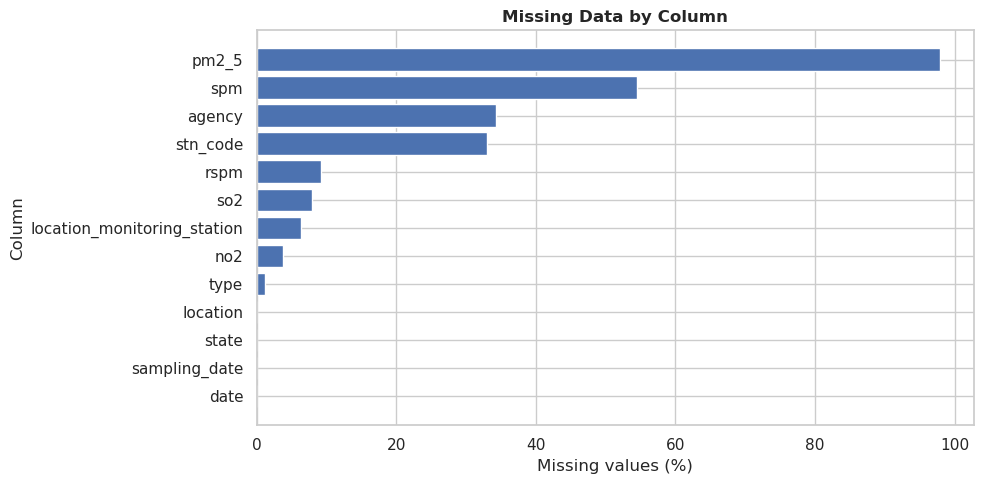

In [3]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2),
    "Data Type": df.dtypes.astype(str)
}).sort_values("Missing Percentage", ascending=False)

display(missing_summary)

print(f"Exact duplicate rows: {df.duplicated().sum():,}")
print(f"Total rows: {len(df):,}")

# Visualize missing values by column
missing_plot = missing_summary.sort_values(
    "Missing Percentage", ascending=True
)

plt.figure(figsize=(10, max(5, len(missing_plot) * 0.3)))
plt.barh(
    missing_plot.index,
    missing_plot["Missing Percentage"]
)
plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.title("Missing Data by Column")
plt.tight_layout()
plt.show()

## 4. Data Cleaning and Feature Engineering

The date field will be converted to a datetime format, and pollutant measurements will be converted to numeric values.

We will create year, month, and season variables to support temporal analysis. Invalid dates will be excluded from time-based analyses, while missing pollutant values will remain missing.

For this project, the seasons are simplified analytical groupings:
- Winter: December–February
- Pre-monsoon: March–May
- Monsoon: June–September
- Post-monsoon: October–November

These are broad groupings for exploratory analysis, not a substitute for location-specific meteorological seasons.

In [4]:
# Standardize column names for easier processing
df.columns = df.columns.str.strip().str.lower()

# Confirm whether the expected date field exists
if "date" not in df.columns:
    raise ValueError(
        "A 'date' column was not found. Check the dataset columns above."
    )

# Convert dates and retain records with valid dates
df["date"] = pd.to_datetime(df["date"], errors="coerce")

invalid_dates = df["date"].isna().sum()
print(f"Records with invalid or missing dates: {invalid_dates:,}")

df = df.dropna(subset=["date"]).copy()

# Create time-based features
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.strftime("%b")

season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
}

df["season"] = df["month"].map(season_map)

# Convert known pollutant columns to numeric where present
pollutants = ["so2", "no2", "rspm", "spm", "pm2_5"]
available_pollutants = [col for col in pollutants if col in df.columns]

for col in available_pollutants:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Available pollutant columns:", available_pollutants)
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Records available after date cleaning:", f"{len(df):,}")

display(df.head())

Records with invalid or missing dates: 7
Available pollutant columns: ['so2', 'no2', 'rspm', 'spm', 'pm2_5']
Date range: 1987-01-01 to 2015-12-31
Records available after date cleaning: 435,735


,stn_code,sampling_date,state,location,agency,type,so2,no2,rspm,spm,location_monitoring_station,pm2_5,date,year,month,month_name,season
0,150,February - M021990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",4.8,17.4,NaN,NaN,NaN,NaN,1990-02-01,1990,2,Feb,Winter
1,151,February - M021990,Andhra Pradesh,Hyderabad,NaN,Industrial Area,3.1,7.0,NaN,NaN,NaN,NaN,1990-02-01,1990,2,Feb,Winter
2,152,February - M021990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",6.2,28.5,NaN,NaN,NaN,NaN,1990-02-01,1990,2,Feb,Winter
3,150,March - M031990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",6.3,14.7,NaN,NaN,NaN,NaN,1990-03-01,1990,3,Mar,Pre-monsoon
4,151,March - M031990,Andhra Pradesh,Hyderabad,NaN,Industrial Area,4.7,7.5,NaN,NaN,NaN,NaN,1990-03-01,1990,3,Mar,Pre-monsoon


## 5. Select a Pollutant for Analysis

The dataset may contain measurements such as SO₂, NO₂, RSPM, SPM, and PM2.5. Availability and completeness can differ by pollutant.

For the initial analysis, we will use RSPM (respirable suspended particulate matter) if available. We will check the number of valid observations before interpreting any chart.

**Interpretation principle:** A trend based on sparse or changing monitoring coverage may not represent a true change in pollution. Observation counts must be reviewed alongside pollutant values.

,Valid Observations,Missing Percentage
no2,419505,3.72
so2,401092,7.95
rspm,395516,9.23
spm,198355,54.48
pm2_5,9314,97.86


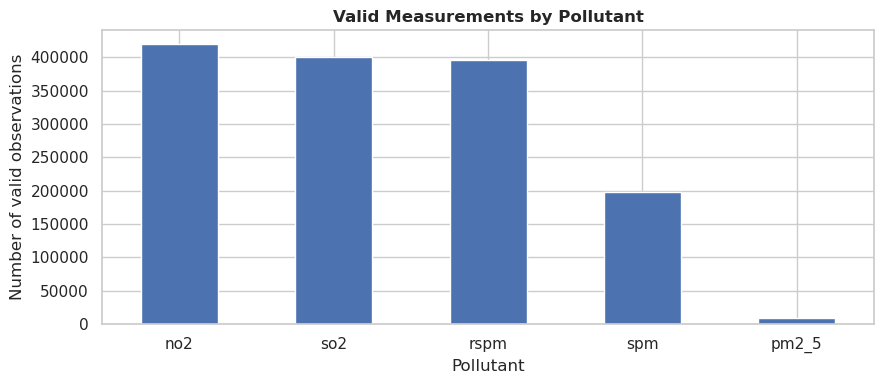

Primary pollutant selected: rspm


In [5]:
if not available_pollutants:
    print("No expected pollutant columns were found.")
else:
    coverage = pd.DataFrame({
        "Valid Observations": df[available_pollutants].notna().sum(),
        "Missing Percentage": (
            df[available_pollutants].isna().mean() * 100
        ).round(2)
    }).sort_values("Valid Observations", ascending=False)

    display(coverage)

    coverage["Valid Observations"].plot(
        kind="bar", figsize=(9, 4)
    )
    plt.title("Valid Measurements by Pollutant")
    plt.xlabel("Pollutant")
    plt.ylabel("Number of valid observations")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

# Choose the primary pollutant if available
primary_pollutant = (
    "rspm" if "rspm" in available_pollutants
    else available_pollutants[0] if available_pollutants
    else None
)

print("Primary pollutant selected:", primary_pollutant)

## 6. Historical Pollution Trends

This section examines how recorded pollutant concentrations changed over the years covered by the dataset.

We will calculate both the mean and median annual concentration. The median is useful because pollution measurements may be skewed by extreme observations. We will also display the number of valid measurements for each year.

The results describe the available records; they do not automatically establish why pollution changed.

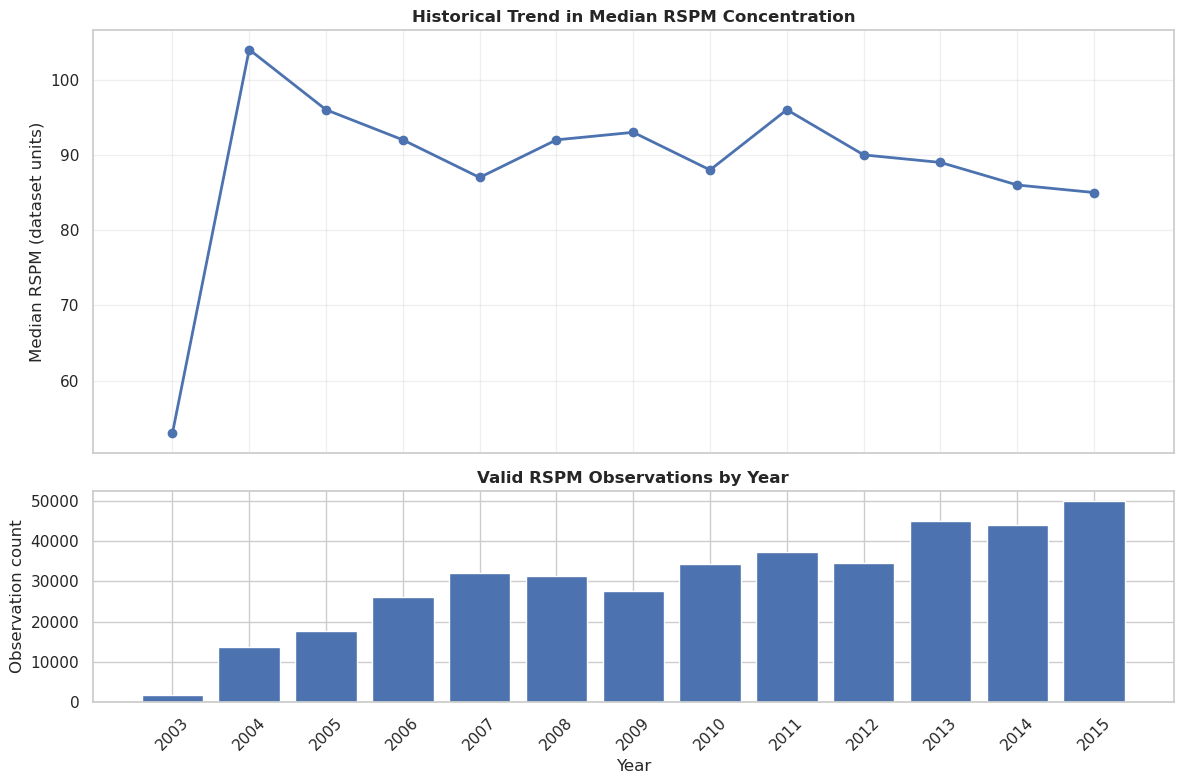

,year,median_rspm,mean_rspm,observations
0,2003,53.0,88.706643,1701
1,2004,104.0,121.152107,13724
2,2005,96.0,111.497940,17715
3,2006,92.0,109.421053,26049
4,2007,87.0,104.559196,32080
5,2008,92.0,112.879093,31363
6,2009,93.0,114.330681,27649
7,2010,88.0,110.575186,34437
8,2011,96.0,115.800038,37188
9,2012,90.0,110.010378,34687


In [13]:

# Yearly median RSPM trend — corrected visualization

yearly = (
    df.dropna(subset=["rspm"])
    .groupby("year")
    .agg(
        median_rspm=("rspm", "median"),
        mean_rspm=("rspm", "mean"),
        observations=("rspm", "count")
    )
    .reset_index()
    .sort_values("year")
)

fig, axes = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)

axes[0].plot(
    yearly["year"],
    yearly["median_rspm"],
    marker="o",
    linewidth=2
)
axes[0].set_title("Historical Trend in Median RSPM Concentration")
axes[0].set_ylabel("Median RSPM (dataset units)")
axes[0].grid(True, alpha=0.3)

axes[1].bar(
    yearly["year"],
    yearly["observations"],
    width=0.8
)
axes[1].set_title("Valid RSPM Observations by Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Observation count")
axes[1].set_xticks(yearly["year"])
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

display(yearly)

## 7. Regional Comparison: Which Locations Have Higher Recorded Pollution?

We will compare locations using the median concentration of the selected pollutant.

To reduce the influence of locations with very few records, the initial comparison will include only locations with at least 100 valid observations. This is an analytical threshold, not an official standard, and can be adjusted after reviewing the dataset.

A location ranking is not necessarily a ranking of all Indian cities: monitoring coverage, time periods, and data availability may differ.

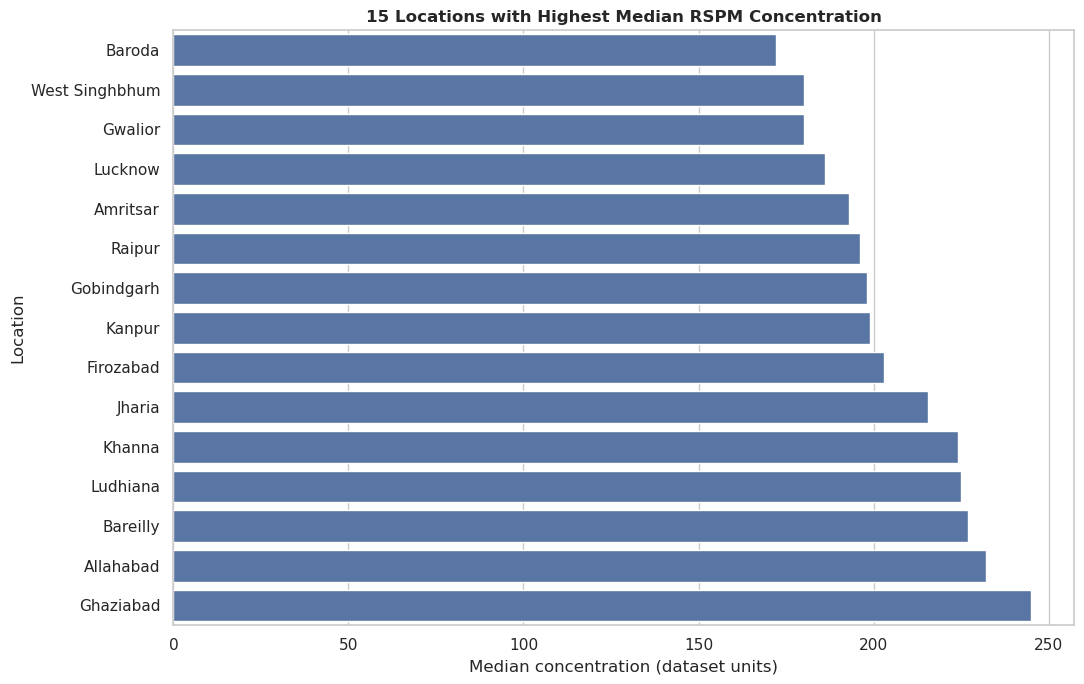

,state,location,median_concentration,mean_concentration,observations
75,Gujarat,Baroda,172.00,179.238702,208
110,Jharkhand,West Singhbhum,180.00,246.417219,151
147,Madhya Pradesh,Gwalior,180.00,201.166626,1227
261,Uttar Pradesh,Lucknow,186.00,188.651219,5713
214,Punjab,Amritsar,193.00,194.208382,859
48,Chhattisgarh,Raipur,196.00,210.202634,1367
219,Punjab,Gobindgarh,198.00,196.303437,3724
259,Uttar Pradesh,Kanpur,199.02,194.387919,6549
254,Uttar Pradesh,Firozabad,203.00,198.940939,1981
106,Jharkhand,Jharia,215.50,210.844414,802


In [7]:
if primary_pollutant and "location" in df.columns:
    group_cols = (
        ["state", "location"] if "state" in df.columns
        else ["location"]
    )

    location_summary = (
        df.dropna(subset=["location", primary_pollutant])
        .groupby(group_cols)
        .agg(
            median_concentration=(primary_pollutant, "median"),
            mean_concentration=(primary_pollutant, "mean"),
            observations=(primary_pollutant, "count")
        )
        .reset_index()
    )

    MIN_OBSERVATIONS = 100

    eligible_locations = location_summary[
        location_summary["observations"] >= MIN_OBSERVATIONS
    ]

    top_locations = eligible_locations.nlargest(
        15, "median_concentration"
    ).sort_values("median_concentration")

    plt.figure(figsize=(11, 7))
    sns.barplot(
        data=top_locations,
        x="median_concentration",
        y="location"
    )
    plt.title(
        f"15 Locations with Highest Median "
        f"{primary_pollutant.upper()} Concentration"
    )
    plt.xlabel("Median concentration (dataset units)")
    plt.ylabel("Location")
    plt.tight_layout()
    plt.show()

    display(top_locations)
else:
    print("Location or pollutant data is unavailable.")

## 8. State-Level Pollution Comparison

Where state information is available, we will compare median pollutant concentrations across states.

This analysis aggregates the available monitoring records. It should not be interpreted as a population-weighted state average, and a state with more monitoring locations may contribute more records than another state.

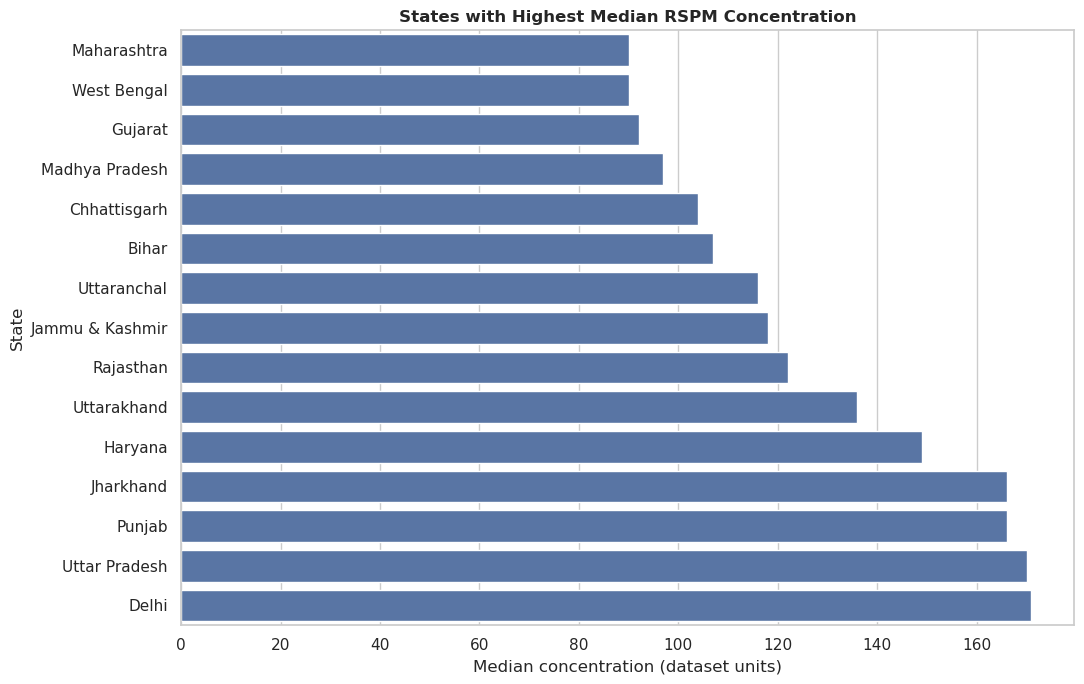

,state,median_concentration,observations,locations
18,Maharashtra,90.0,55437,26
33,West Bengal,90.0,21295,18
10,Gujarat,92.0,19072,16
17,Madhya Pradesh,97.0,16874,14
5,Chhattisgarh,104.0,6764,5
3,Bihar,107.0,1333,1
32,Uttaranchal,116.0,265,1
13,Jammu & Kashmir,118.0,1257,1
26,Rajasthan,122.0,22954,5
31,Uttarakhand,136.0,1917,6


In [8]:
if primary_pollutant and "state" in df.columns:
    state_summary = (
        df.dropna(subset=["state", primary_pollutant])
        .groupby("state")
        .agg(
            median_concentration=(primary_pollutant, "median"),
            observations=(primary_pollutant, "count"),
            locations=("location", "nunique")
            if "location" in df.columns
            else (primary_pollutant, "count")
        )
        .reset_index()
    )

    state_summary = state_summary[
        state_summary["observations"] >= 100
    ]

    state_plot = state_summary.nlargest(
        15, "median_concentration"
    ).sort_values("median_concentration")

    plt.figure(figsize=(11, 7))
    sns.barplot(
        data=state_plot,
        x="median_concentration",
        y="state"
    )
    plt.title(
        f"States with Highest Median "
        f"{primary_pollutant.upper()} Concentration"
    )
    plt.xlabel("Median concentration (dataset units)")
    plt.ylabel("State")
    plt.tight_layout()
    plt.show()

    display(state_plot)
else:
    print("State or pollutant data is unavailable.")

## 9. Monthly and Seasonal Patterns

Pollution concentrations can vary across months because of weather, emissions, atmospheric conditions, and other factors.

We will examine monthly medians and simplified seasonal groupings to see whether the dataset contains recurring patterns. These comparisons are exploratory and do not establish the causes of seasonal variation.

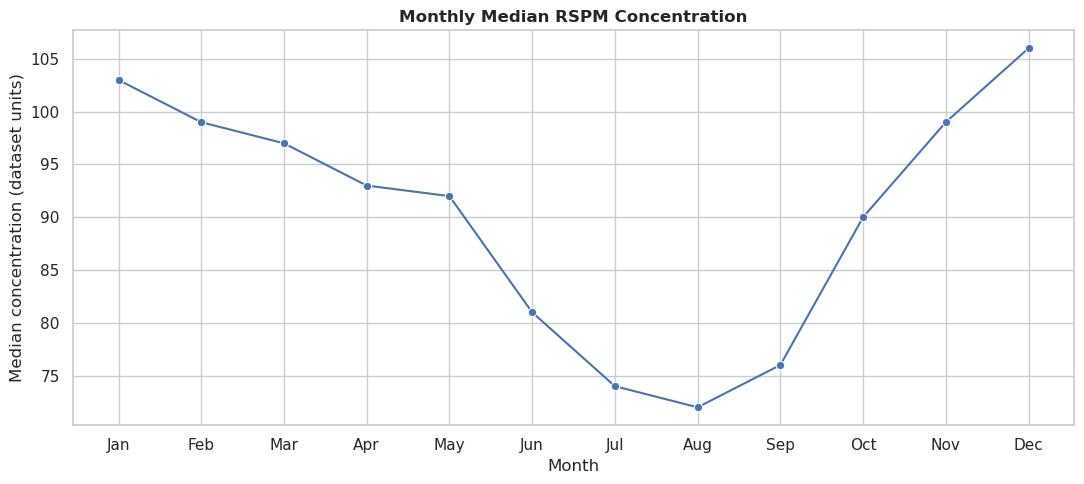

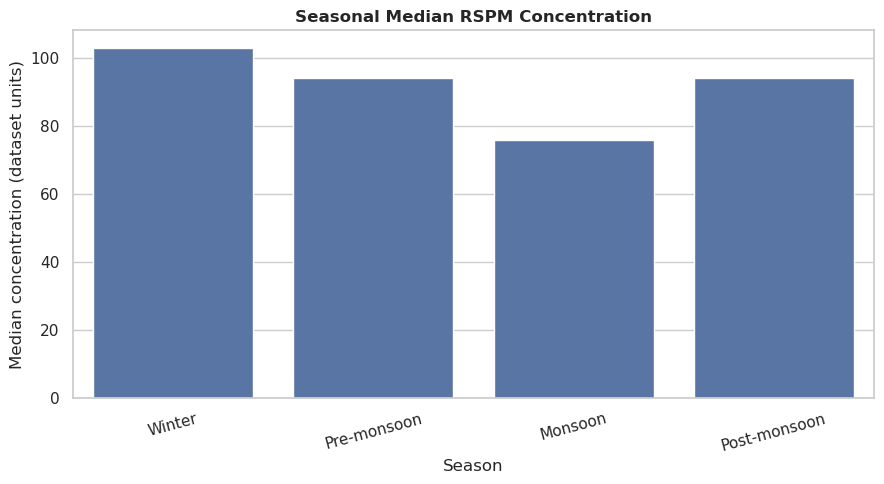

,season,median_concentration,mean_concentration,observations
0,Winter,103.0,121.888200,96021
1,Pre-monsoon,94.0,113.024470,101832
2,Monsoon,76.0,93.498531,130879
3,Post-monsoon,94.0,113.723345,66784


In [9]:
if primary_pollutant:
    monthly = (
        df.dropna(subset=[primary_pollutant])
        .groupby("month")
        .agg(
            median_concentration=(primary_pollutant, "median"),
            observations=(primary_pollutant, "count")
        )
        .reindex(range(1, 13))
        .reset_index()
    )

    month_labels = [
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ]

    plt.figure(figsize=(11, 5))
    sns.lineplot(
        data=monthly,
        x="month",
        y="median_concentration",
        marker="o"
    )
    plt.xticks(range(1, 13), month_labels)
    plt.title(
        f"Monthly Median {primary_pollutant.upper()} Concentration"
    )
    plt.xlabel("Month")
    plt.ylabel("Median concentration (dataset units)")
    plt.tight_layout()
    plt.show()

    seasonal_order = [
        "Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"
    ]

    seasonal = (
        df.dropna(subset=[primary_pollutant, "season"])
        .groupby("season")
        .agg(
            median_concentration=(primary_pollutant, "median"),
            mean_concentration=(primary_pollutant, "mean"),
            observations=(primary_pollutant, "count")
        )
        .reindex(seasonal_order)
        .reset_index()
    )

    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=seasonal,
        x="season",
        y="median_concentration"
    )
    plt.title(
        f"Seasonal Median {primary_pollutant.upper()} Concentration"
    )
    plt.xlabel("Season")
    plt.ylabel("Median concentration (dataset units)")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

    display(seasonal)

The exploratory Kruskal–Wallis test indicates statistically significant differences in pooled RSPM distributions across the selected seasons (H = 11,970.354, p < 0.001). Median RSPM was highest in winter (103) and lowest during the monsoon season (76) in this dataset. Because observations may be repeated within monitoring locations and coverage differs across locations and time, this result should be treated as exploratory rather than definitive evidence of a seasonal effect.

## 10. Relationships Between Pollutants

This section explores whether available pollutant measurements tend to move together.

We will calculate correlations using numeric pollutant fields. Correlation indicates the strength and direction of a statistical relationship; it does not establish causation.

Because the measurements may have different levels of missingness and may come from different monitoring conditions, the number of records used in each pairwise comparison should be considered.

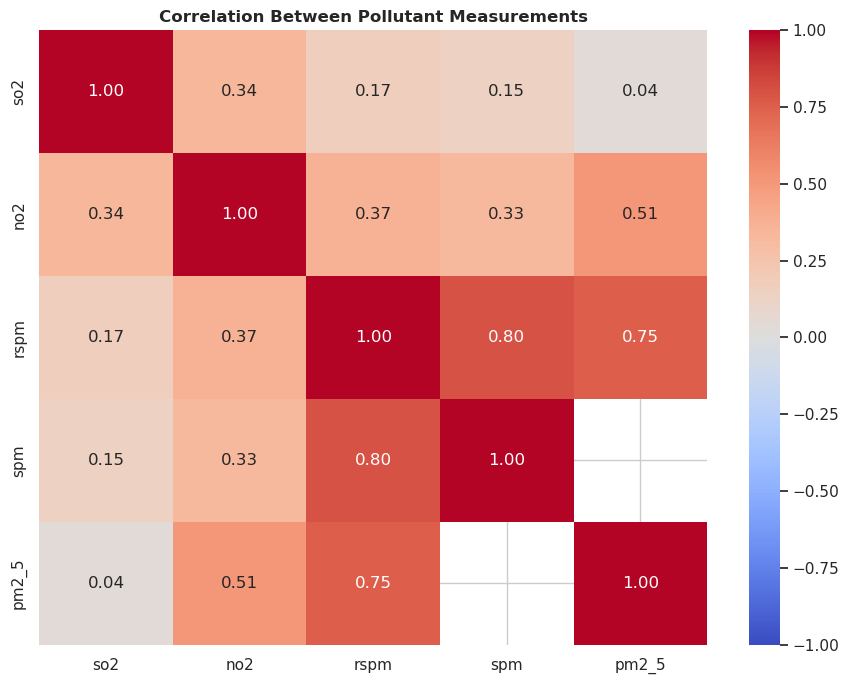

,so2,no2,rspm,spm,pm2_5
so2,401092,399093,366715,172380,9195
no2,399093,419505,383883,189130,9218
rspm,366715,383883,395516,166468,9254
spm,172380,189130,166468,198355,0
pm2_5,9195,9218,9254,0,9314


In [10]:
if len(available_pollutants) >= 2:
    correlation_data = df[available_pollutants].corr()

    plt.figure(figsize=(9, 7))
    sns.heatmap(
        correlation_data,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1
    )
    plt.title("Correlation Between Pollutant Measurements")
    plt.tight_layout()
    plt.show()

    # Report pairwise observation counts
    pair_counts = df[available_pollutants].notna().astype(int).T @ (
        df[available_pollutants].notna().astype(int)
    )
    display(pair_counts)
else:
    print("At least two pollutant columns are needed for correlation.")

## 11. Initial Hypotheses for Further Investigation

Based on the exploratory visualizations, we can formulate hypotheses to test more rigorously.

**Hypothesis 1 — Seasonal variation**

- Null hypothesis (H₀): Median pollutant concentrations do not differ across the selected seasons.
- Alternative hypothesis (H₁): At least one season differs.

**Hypothesis 2 — Differences between locations**

- Null hypothesis (H₀): The distributions of recorded pollutant concentrations are similar across selected locations.
- Alternative hypothesis (H₁): At least one location has a different distribution.

**Hypothesis 3 — Historical changes**

- Null hypothesis (H₀): There is no meaningful temporal trend in the recorded measurements.
- Alternative hypothesis (H₁): A temporal trend is present.

These hypotheses should be refined after inspecting the actual data. Formal testing must account for sample size, outliers, repeated observations, monitoring coverage, and the assumptions of the selected statistical test.

In [11]:
from scipy.stats import kruskal

if primary_pollutant:
    season_groups = []

    for season_name in seasonal_order:
        values = df.loc[
            df["season"] == season_name,
            primary_pollutant
        ].dropna()

        if len(values) > 0:
            season_groups.append((season_name, values))

    if len(season_groups) >= 2:
        statistic, p_value = kruskal(
            *[values for _, values in season_groups]
        )

        print("Kruskal–Wallis seasonal comparison")
        print(f"H statistic: {statistic:.3f}")
        print(f"P-value: {p_value:.6g}")

        if p_value < 0.05:
            print(
                "The result is statistically significant at the "
                "5% level. At least one group may differ."
            )
        else:
            print(
                "The result is not statistically significant at "
                "the 5% level."
            )

        print(
            "\nNote: Statistical significance does not imply "
            "practical importance or causation."
        )
    else:
        print("Insufficient seasonal groups for this test.")

Kruskal–Wallis seasonal comparison
H statistic: 11970.354
P-value: 0
The result is statistically significant at the 5% level. At least one group may differ.

Note: Statistical significance does not imply practical importance or causation.


## 12. Policy Context and Limitations

An important question is whether historical pollution patterns coincide with environmental policy changes or other major events.

Before examining any policy period, verify the actual date range of the dataset. If the data does not cover the period before and after a policy was introduced, it cannot support a meaningful before-and-after analysis of that policy.

Even when both periods are covered, a simple comparison cannot establish that a policy caused a change. Weather, economic activity, emissions, monitoring coverage, and other interventions may also influence measurements.

### Key Limitations to Document

- Missing or incomplete pollutant measurements.
- Uneven numbers of records across years and locations.
- Possible changes in monitoring coverage over time.
- Potentially skewed measurements and extreme values.
- Simplified seasonal groupings.
- Observational data that cannot independently establish causation.
- Pollutant concentration measurements that should not be confused with AQI.


## 14. Optional Baseline Model: Predicting Pollutant Concentration

If the dataset has sufficient coverage for a selected location, we can build a baseline model to predict the selected pollutant concentration from historical time features.

The model will use earlier observations for training and later observations for testing. This avoids the main leakage risk of randomly splitting time-dependent observations.

The model's performance will be compared against a simple baseline. Results will be interpreted as an exploratory forecasting exercise, not as a public-health prediction system.

Selected location: Guwahati
Training observations: 2228
Testing observations: 557


,Model,MAE,RMSE,R2
0,Median baseline,46.575853,55.349985,-0.016413
1,Random Forest,59.002584,66.327551,-0.459565


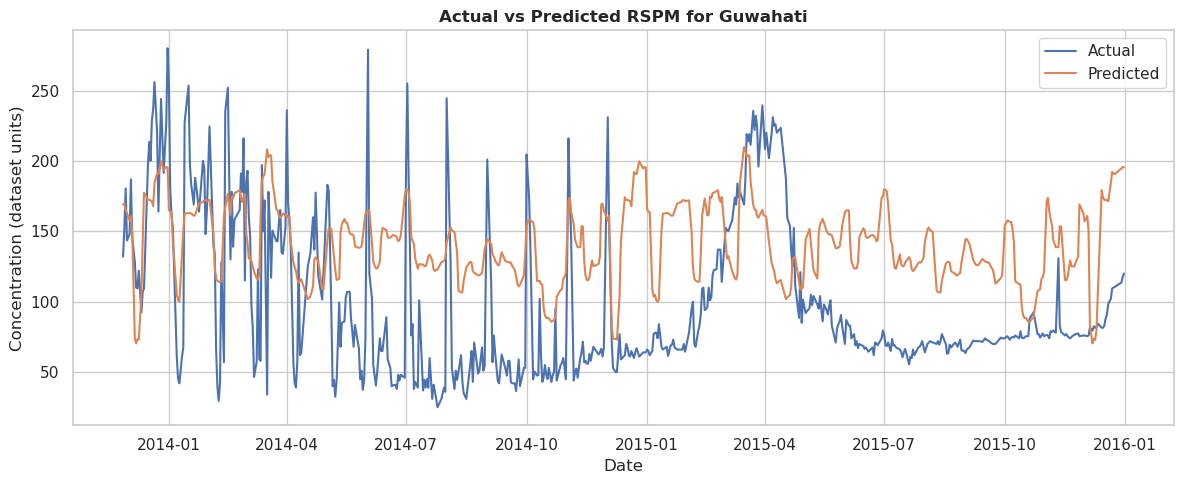

In [12]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

if primary_pollutant is None or "location" not in df.columns:
    print("A pollutant and location column are required for modeling.")
else:
    # Choose the location with the most valid observations.
    counts = (
        df.dropna(subset=[primary_pollutant, "location"])
        .groupby("location")[primary_pollutant]
        .count()
        .sort_values(ascending=False)
    )

    if len(counts) == 0 or counts.iloc[0] < 100:
        print("Insufficient observations for a meaningful baseline model.")
    else:
        chosen_location = counts.index[0]

        model_df = df.loc[
            df["location"] == chosen_location,
            ["date", primary_pollutant]
        ].dropna().copy()

        # Aggregate records by day to create a daily series.
        model_df = (
            model_df.groupby("date")[primary_pollutant]
            .median()
            .reset_index()
            .sort_values("date")
        )

        model_df["month"] = model_df["date"].dt.month
        model_df["day_of_year"] = model_df["date"].dt.dayofyear
        model_df["year"] = model_df["date"].dt.year

        if len(model_df) < 100:
            print("Not enough dated observations for this model.")
        else:
            X = model_df[["month", "day_of_year", "year"]]
            y = model_df[primary_pollutant]

            split_idx = int(len(model_df) * 0.8)

            X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
            y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

            baseline = DummyRegressor(strategy="median")
            baseline.fit(X_train, y_train)
            baseline_pred = baseline.predict(X_test)

            model = RandomForestRegressor(
                n_estimators=200,
                random_state=42,
                min_samples_leaf=3
            )
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)

            results = pd.DataFrame({
                "Model": ["Median baseline", "Random Forest"],
                "MAE": [
                    mean_absolute_error(y_test, baseline_pred),
                    mean_absolute_error(y_test, predictions)
                ],
                "RMSE": [
                    np.sqrt(mean_squared_error(y_test, baseline_pred)),
                    np.sqrt(mean_squared_error(y_test, predictions))
                ],
                "R2": [
                    r2_score(y_test, baseline_pred),
                    r2_score(y_test, predictions)
                ]
            })

            print("Selected location:", chosen_location)
            print("Training observations:", len(X_train))
            print("Testing observations:", len(X_test))
            display(results)

            plt.figure(figsize=(12, 5))
            plt.plot(
                model_df["date"].iloc[split_idx:],
                y_test.values,
                label="Actual"
            )
            plt.plot(
                model_df["date"].iloc[split_idx:],
                predictions,
                label="Predicted"
            )
            plt.title(
                f"Actual vs Predicted {primary_pollutant.upper()} "
                f"for {chosen_location}"
            )
            plt.xlabel("Date")
            plt.ylabel("Concentration (dataset units)")
            plt.legend()
            plt.tight_layout()
            plt.show()